# Demo 1: the manuscript's results

Every table and figure the manuscript reports for Demo 1, drawn from the forecast
ensembles. `01-model-and-forecast.ipynb` shows the models and one forecast; this is that
forecast repeated at all 25 weekly forecast dates, at two ensemble seeds, and scored.

Nothing here fits a model. The ensembles come from `scripts/run-demos.sh` (hours), and
`scripts/build-figures.sh` writes these same tables and figures to `results/demos/` from
the same functions, so this notebook and the paper cannot disagree.

| model | structure |
|---|---|
| `multi-strata-empirical` | six age groups, mixing by a measured contact matrix |
| `multi-strata-homogeneous` | the same six age groups, mixing in proportion to group size |
| `single-strata` | one population, no age structure |

## Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from manuscript_analysis.demos import export, tables
from manuscript_analysis.demos.flu import evaluation
from manuscript_analysis.demos.lib.figures import use_manuscript_style

use_manuscript_style()
pd.set_option("display.width", 200)

## Load and score

Seed 0 is the manuscript run and seed 1 its replicate; both are scored against the one
frozen observations file. Scores are log WIS, as in CDC's FluSight evaluations, and the
skill table also reports the natural scale.

In [2]:
ev = evaluation.load()
replicate = evaluation.load_replicate()
natural = evaluation.load(scale="natural")

first, last = (pd.Timestamp(d).date() for d in (ev.origins[0], ev.origins[-1]))
print(f"{len(ev.origins)} forecast dates, {first} to {last}; "
      f"horizons {list(ev.horizons)}; {len(ev.locations)} jurisdictions scored")

25 forecast dates, 2025-11-22 to 2026-05-09; horizons [0, 1, 2, 3]; 51 jurisdictions scored


In [3]:
# The models must differ ONLY in structure, or the comparison is not controlled.
for label, loaded in (("seed 0", ev), ("seed 1", replicate)):
    settings = {
        name: tuple(run.info[k] for k in ("season", "season_start", "season_weeks",
                                          "num_realizations", "burn_in_weeks",
                                          "horizon_weeks", "seed"))
        for name, run in loaded.runs.items()
    }
    assert len(set(settings.values())) == 1, f"{label}: models were not run identically"
    print(f"{label}: all {len(settings)} models run identically "
          f"(R = {next(iter(settings.values()))[3]})")

seed 0: all 3 models run identically (R = 300)
seed 1: all 3 models run identically (R = 300)


## Tables

**`flu-skill`**: forecast skill by model, both scales, with coverage.

In [4]:
tables.flu_skill(ev, natural)

,WIS,rel WIS,log WIS,rel log WIS,h0,h1,h2,h3,cov95,cov50
model,,,,,,,,,,
empirical mixing,117.540,0.915,0.403,0.961,0.218,0.353,0.472,0.569,0.767,0.335
homogeneous mixing,156.992,1.042,0.450,1.046,0.240,0.388,0.527,0.646,0.737,0.330
no age structure,141.144,1.000,0.423,1.000,0.216,0.361,0.499,0.616,0.754,0.340


**`flu-reproducibility`**: the headline comparison at both seeds.

In [5]:
tables.flu_reproducibility(ev, replicate)

median ratio better in        p
model              seed                                 
empirical mixing   0            0.959  35 of 51  1.1e-02
                   1            0.948  38 of 51  6.2e-04
homogeneous mixing 0            1.042  16 of 51  1.1e-02
                   1            1.017  22 of 51  4.0e-01

**`flu-by-jurisdiction`**: every scored jurisdiction. A reference table, not a ranking: the
distribution of the ratio is reproducible across seeds, the per-jurisdiction order is not.

In [6]:
tables.flu_by_jurisdiction(ev)

,empirical mixing,homogeneous mixing,no age structure,empirical / baseline,multi-strata-homogeneous / single-strata
jurisdiction,,,,,
SD,0.571,0.948,0.702,0.735,1.178
NE,0.452,0.629,0.612,0.764,0.976
WV,0.542,0.683,0.707,0.787,0.962
DE,0.341,0.506,0.450,0.856,1.070
VT,0.544,0.577,0.689,0.857,0.871
MA,0.304,0.374,0.363,0.866,1.038
IA,0.432,0.413,0.509,0.867,0.821
MN,0.341,0.417,0.391,0.891,1.042
MO,0.395,0.467,0.446,0.892,1.022


## Figures

`export` composes these from panel functions in `flu/evaluation.py`. They display here
but are written to `results/demos/figures/` only by `scripts/build-figures.sh`.

**Figure 2**: contact structures, skill by horizon, the fit by age group, and the
per-jurisdiction ratio at both seeds.

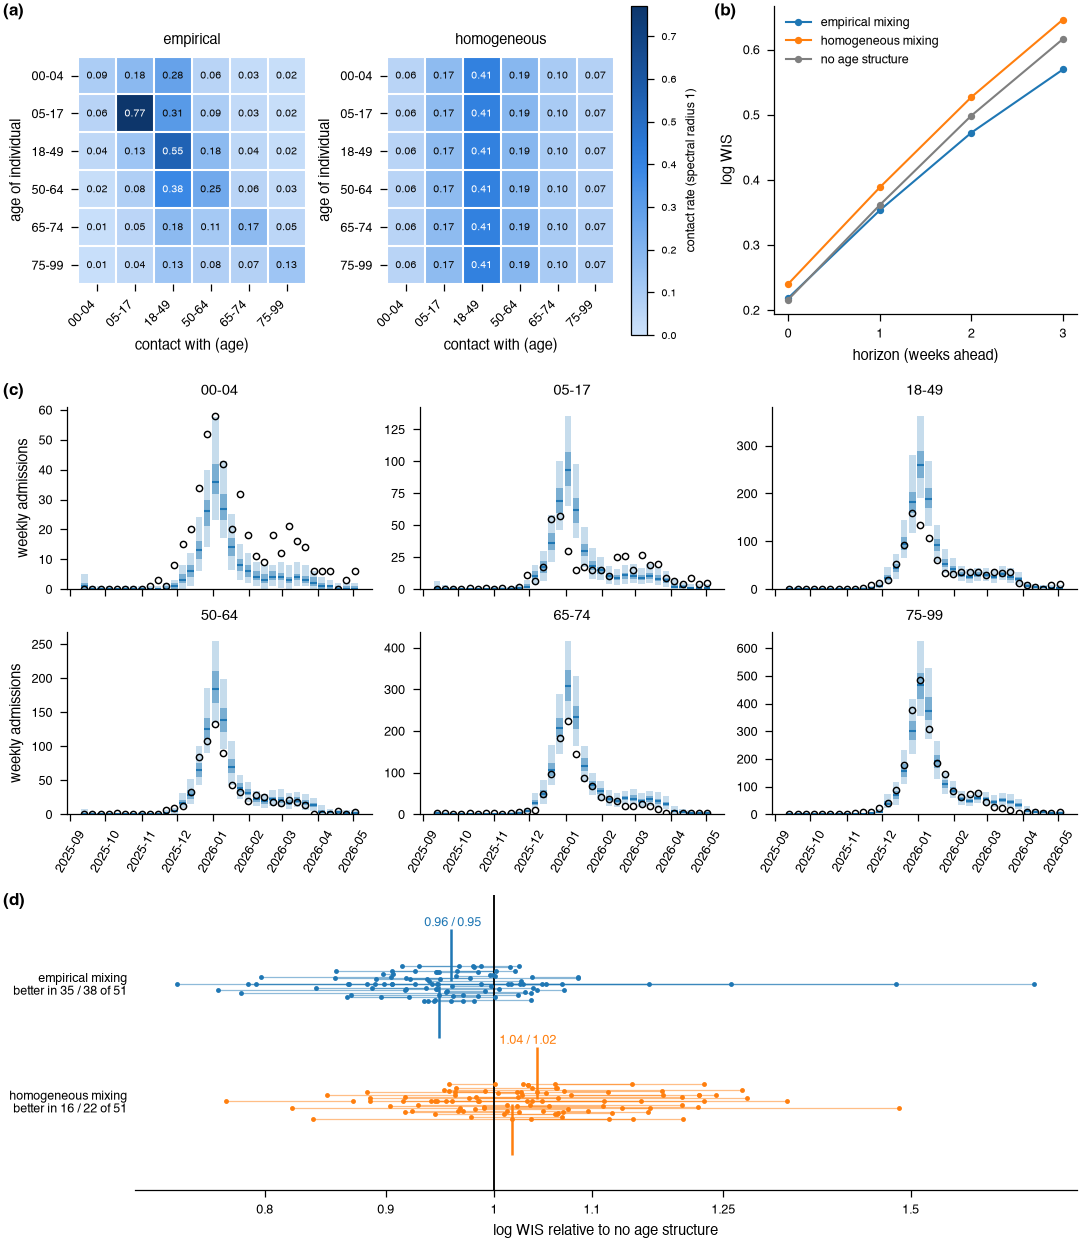

In [7]:
fig = export.figure_2_flu(ev, replicate)
plt.show()

**Supplementary forecast figure**: the same forecasts at the model's own age groups (the
darker shade) and at the state totals they are scored at.

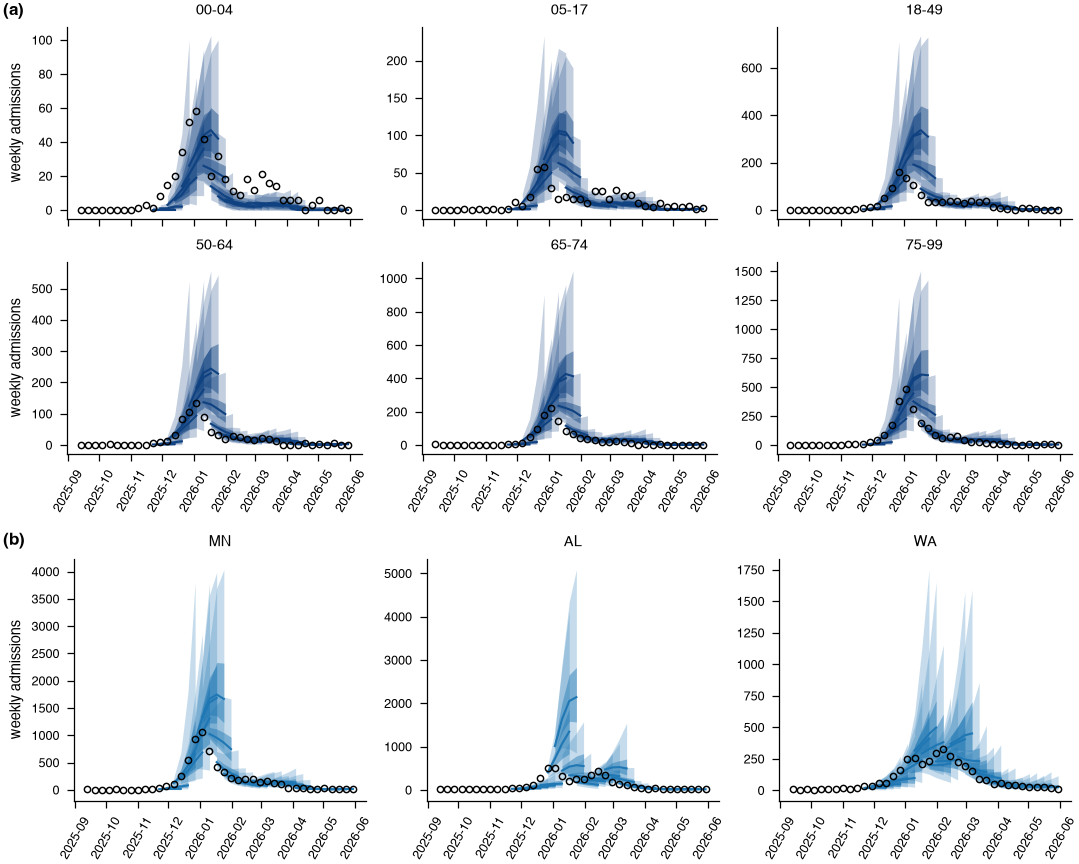

In [8]:
fig = export.figure_s_flu_forecasts(ev)
plt.show()

**Supplementary calibration figure, Demo 1's panel**: coverage of the central intervals
against their nominal level. All three models are under-dispersed.

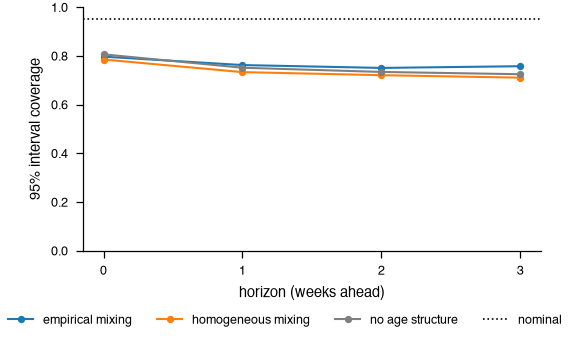

In [9]:
fig = evaluation.figure_calibration(ev, nominal=0.95)
plt.show()